# CreditGuard AI
## Credit Card Default Prediction Using Machine Learning

### Objective
To predict whether a credit card customer is likely to default on their payment next month using machine learning.

### Dataset
UCI Default of Credit Card Clients Dataset

### Models
- Dummy Classifier
- Logistic Regression
- Random Forest Classifier

### Evaluation Metrics
Precision, Recall, F1-score, ROC-AUC, and Confusion Matrix.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

In [27]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("CreditGuard AI project started successfully!")

CreditGuard AI project started successfully!


In [28]:
file_path = "../data/default of credit card clients.xls"

df = pd.read_excel(file_path, header=1)

df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [29]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:", df["ID"].duplicated().sum())

Missing values in each column:


ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0


In [30]:
print("Target column:", df.columns[-1])

print("\nTarget value counts:")
display(df.iloc[:, -1].value_counts())

print("\nTarget value percentages:")
display(
    (df.iloc[:, -1].value_counts(normalize=True) * 100).round(2)
)

Target column: default payment next month

Target value counts:


default payment next month
0    23364
1     6636
Name: count, dtype: int64


Target value percentages:


default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

In [31]:
# Rename the target column
df.columns = df.columns.str.strip()

df = df.rename(columns={
    "default payment next month": "DEFAULT_NEXT_MONTH"
})

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Handle unusual category codes
df["EDUCATION"] = df["EDUCATION"].replace([0, 5, 6], 4)
df["MARRIAGE"] = df["MARRIAGE"].replace(0, 3)

print("Data cleaning completed!")
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
display(df["DEFAULT_NEXT_MONTH"].value_counts())

Data cleaning completed!
Dataset shape: (30000, 25)

Target distribution:


DEFAULT_NEXT_MONTH
0    23364
1     6636
Name: count, dtype: int64

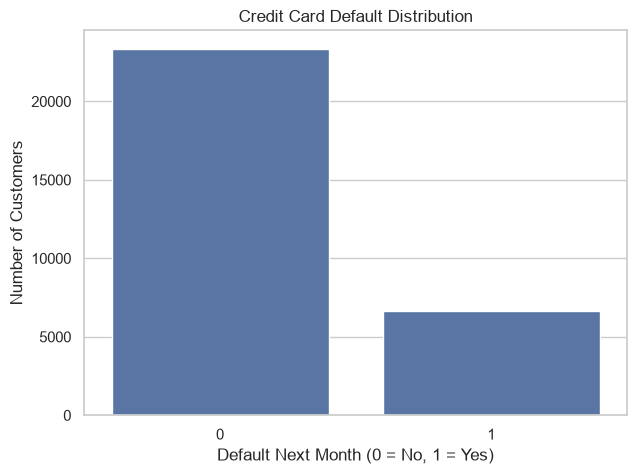

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="DEFAULT_NEXT_MONTH"
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Next Month (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

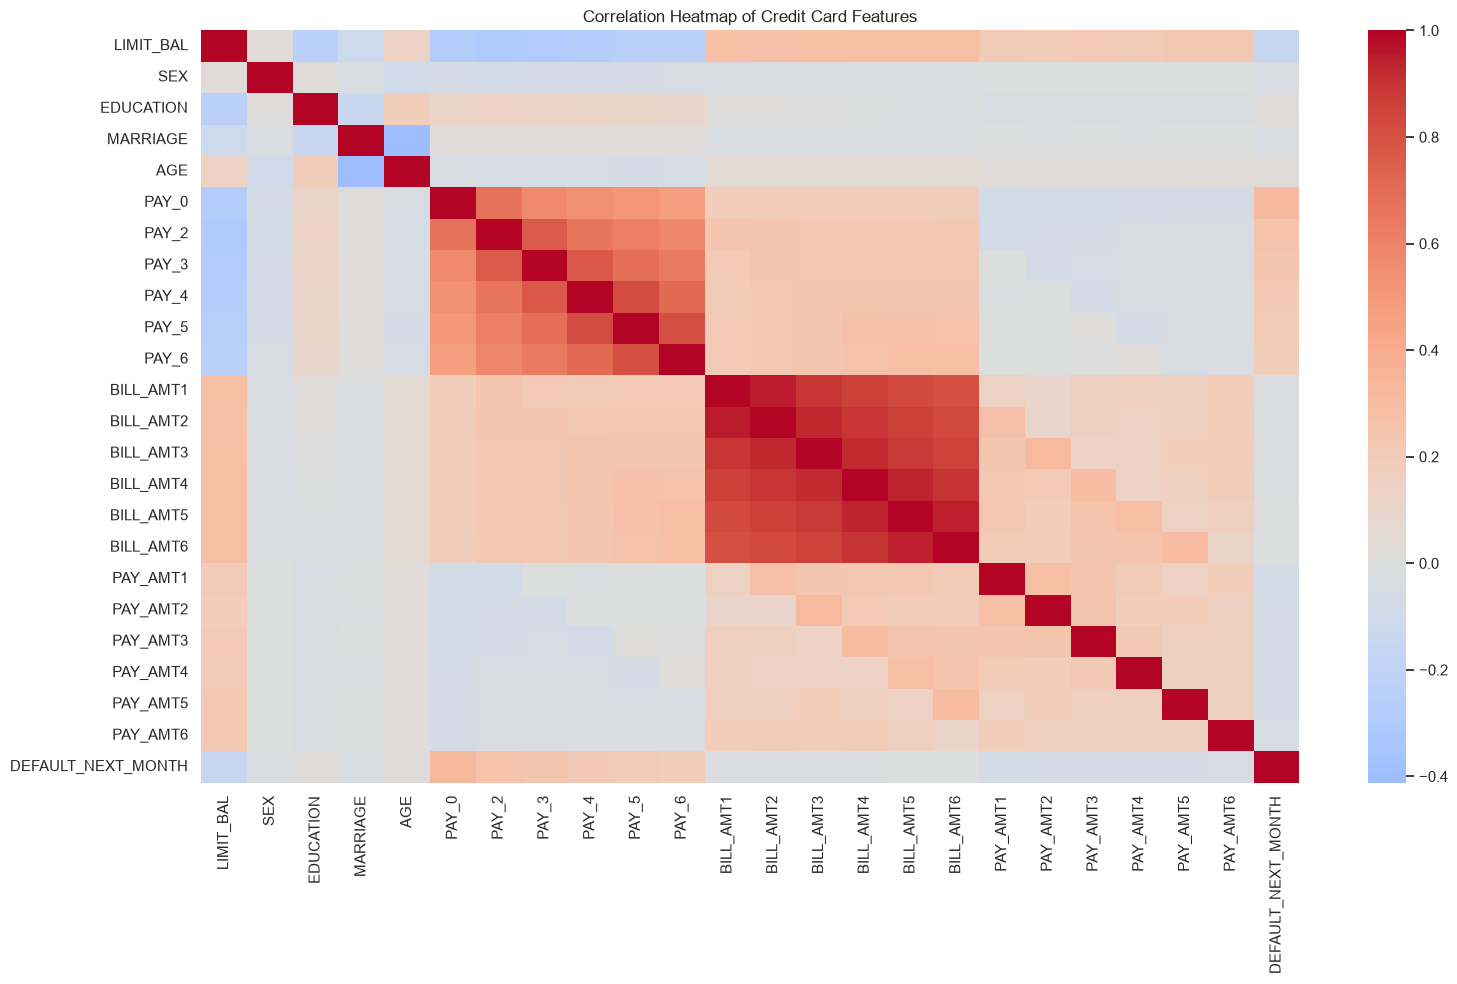

In [33]:
plt.figure(figsize=(16, 10))

corr = df.drop(columns=["ID"]).corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.savefig("../outputs/correlation_heatmap.png", dpi=300)
plt.show()

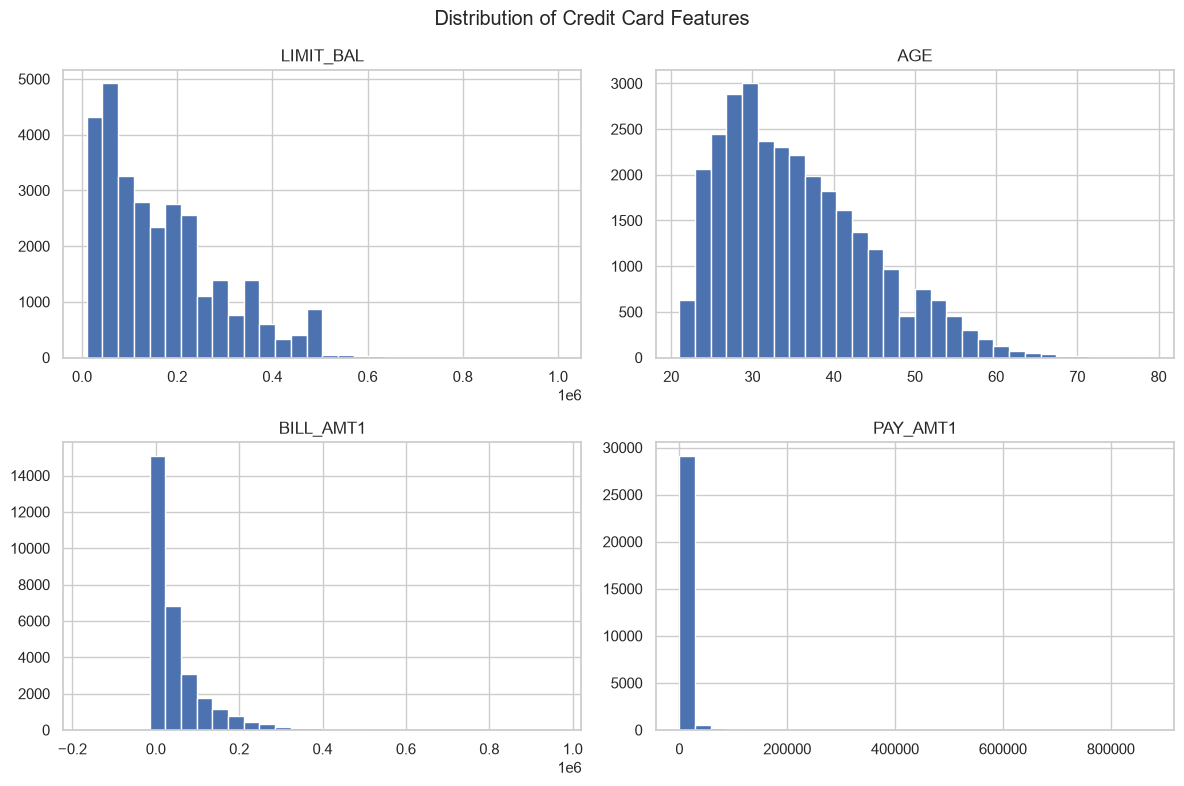

In [34]:
columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1"
]

df[columns].hist(figsize=(12, 8), bins=30)

plt.suptitle("Distribution of Credit Card Features")
plt.tight_layout()
plt.savefig("../outputs/numerical_distributions.png", dpi=300)
plt.show()

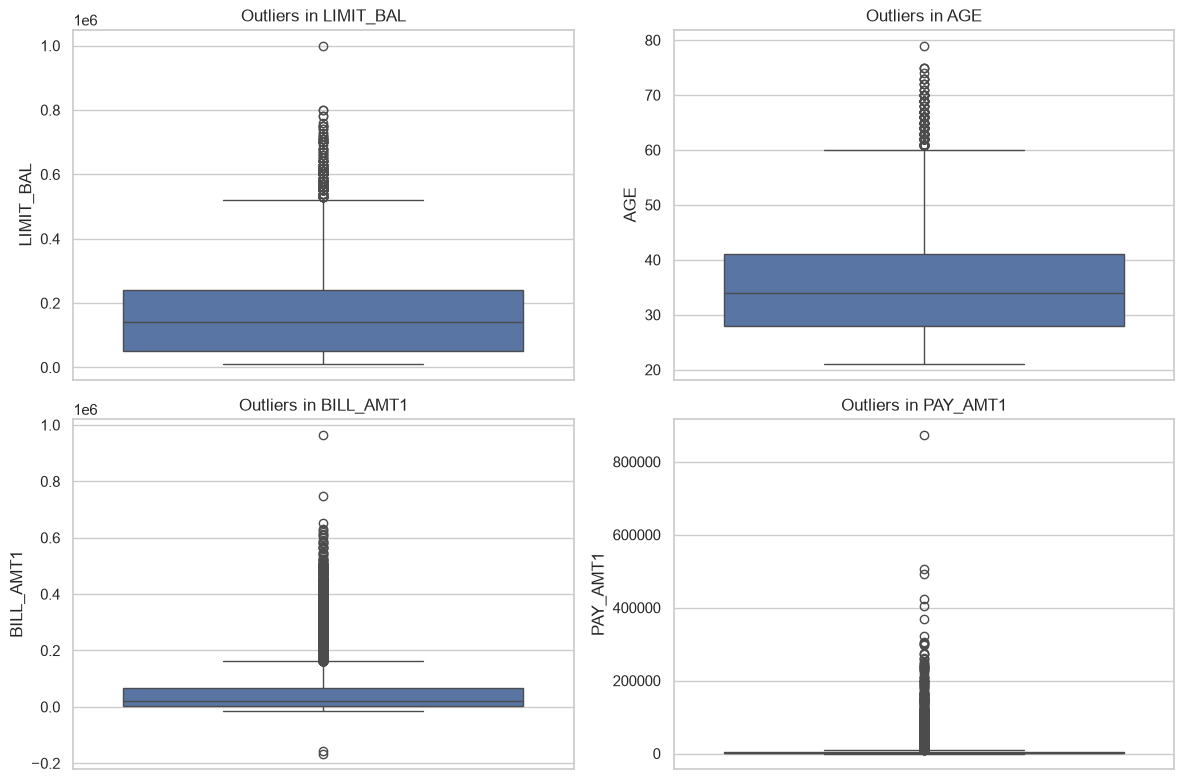

In [35]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(
    ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"], 1
):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.savefig("../outputs/outlier_boxplots.png", dpi=300)
plt.show()

In [36]:
# Historical bill and payment columns
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
status_cols = ["PAY_0", "PAY_2", "PAY_3",
               "PAY_4", "PAY_5", "PAY_6"]

# Create new features
df["AVG_BILL_AMOUNT"] = df[bill_cols].mean(axis=1)
df["AVG_PAYMENT_AMOUNT"] = df[pay_cols].mean(axis=1)
df["DELAYED_MONTHS"] = (df[status_cols] > 0).sum(axis=1)

df["AVG_BILL_TO_LIMIT_RATIO"] = (
    df["AVG_BILL_AMOUNT"] /
    df["LIMIT_BAL"].replace(0, np.nan)
)

print("Feature engineering completed!")
display(df.head())

Feature engineering completed!


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT_NEXT_MONTH,AVG_BILL_AMOUNT,AVG_PAYMENT_AMOUNT,DELAYED_MONTHS,AVG_BILL_TO_LIMIT_RATIO
0,1,20000,2,2,1,24,2,2,-1,-1,...,689,0,0,0,0,1,1284.000000,114.833333,2,0.064200
1,2,120000,2,2,2,26,-1,2,0,0,...,1000,1000,1000,0,2000,1,2846.166667,833.333333,2,0.023718
2,3,90000,2,2,2,34,0,0,0,0,...,1500,1000,1000,1000,5000,0,16942.166667,1836.333333,0,0.188246
3,4,50000,2,2,1,37,0,0,0,0,...,2019,1200,1100,1069,1000,0,38555.666667,1398.000000,0,0.771113
4,5,50000,1,2,1,57,-1,0,-1,0,...,36681,10000,9000,689,679,0,18223.166667,9841.500000,0,0.364463


In [37]:
X = df.drop(columns=["ID", "DEFAULT_NEXT_MONTH"])
y = df["DEFAULT_NEXT_MONTH"].astype(int)

print("Input features:", X.shape)
print("Target values:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

Input features: (30000, 27)
Target values: (30000,)

Target distribution:


DEFAULT_NEXT_MONTH
0    23364
1     6636
Name: count, dtype: int64

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 24000
Testing records: 6000


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [41]:
models = {
    "Baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Baseline, Logistic Regression, and Random Forest are ready!")

Baseline, Logistic Regression, and Random Forest are ready!


In [42]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Precision,Recall,F1-score,ROC-AUC
0,Baseline,0.000,0.000,0.000,0.500
1,Logistic Regression,0.495,0.578,0.533,0.770
2,Random Forest,0.562,0.501,0.530,0.773


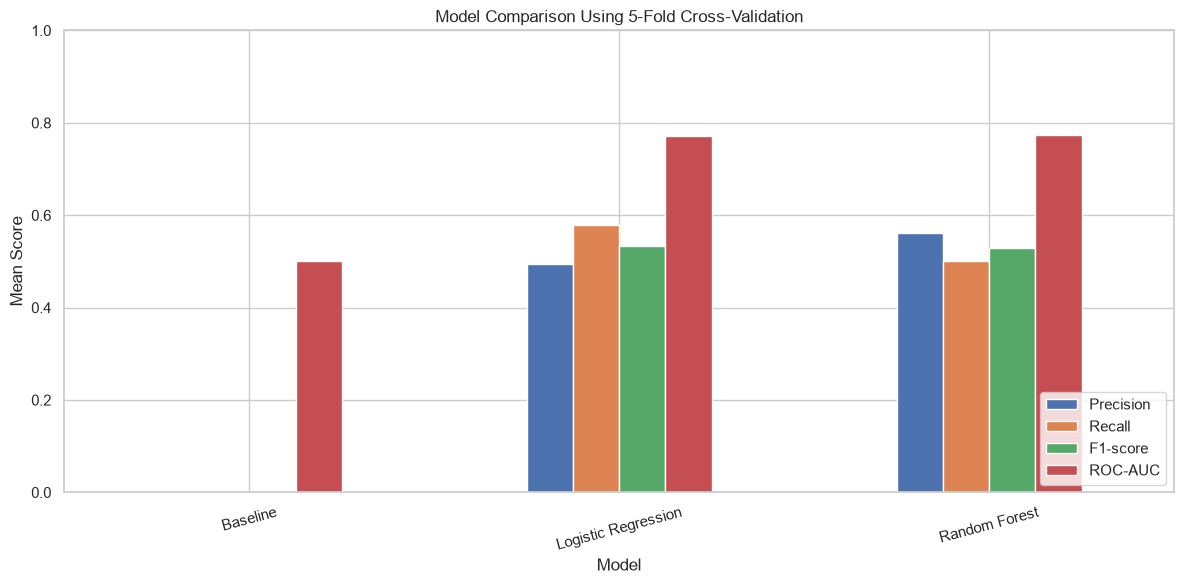

In [43]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.ylabel("Mean Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/model_comparison.png", dpi=300)
plt.show()

In [44]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_grid,
    n_iter=6,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best parameters:")
print(search.best_params_)

print("Best cross-validation F1-score:")
print(round(search.best_score_, 3))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 10}
Best cross-validation F1-score:
0.543


In [45]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("FINAL TEST RESULTS")
for metric, score in test_results.items():
    print(f"{metric}: {score:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

FINAL TEST RESULTS
Accuracy: 0.7722
Precision: 0.4879
Recall: 0.6074
F1-score: 0.5411
ROC-AUC: 0.7786

Detailed Classification Report:
              precision    recall  f1-score   support

  No Default       0.88      0.82      0.85      4673
     Default       0.49      0.61      0.54      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.77      0.78      6000



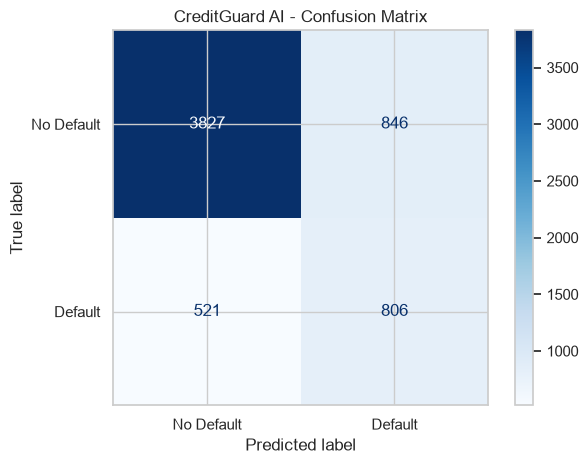

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("CreditGuard AI - Confusion Matrix")
plt.tight_layout()
plt.savefig("../outputs/confusion_matrix.png", dpi=300)
plt.show()

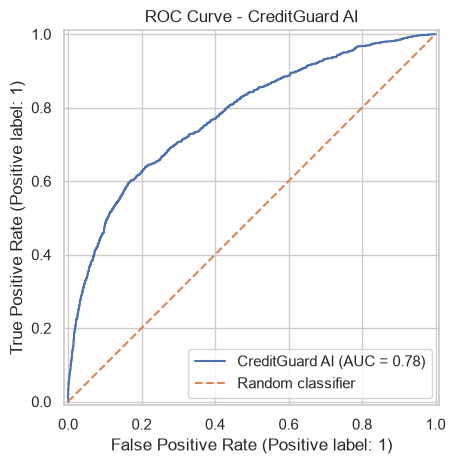

In [47]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="CreditGuard AI"
)

plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.title("ROC Curve - CreditGuard AI")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/roc_curve.png", dpi=300)
plt.show()

In [48]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

joblib.dump(best_model, "../models/creditguard_model.joblib")

pd.DataFrame([test_results]).to_csv(
    "../outputs/test_metrics.csv",
    index=False
)

print("Model and evaluation metrics saved successfully!")

Model and evaluation metrics saved successfully!


,Feature,Importance
16,numeric__DELAYED_MONTHS,0.146350
31,categorical__PAY_0_2,0.090522
42,categorical__PAY_2_2,0.062194
29,categorical__PAY_0_0,0.048269
17,numeric__AVG_BILL_TO_LIMIT_RATIO,0.044719
15,numeric__AVG_PAYMENT_AMOUNT,0.041356
64,categorical__PAY_4_2,0.036312
53,categorical__PAY_3_2,0.034789
0,numeric__LIMIT_BAL,0.032429
8,numeric__PAY_AMT1,0.031069


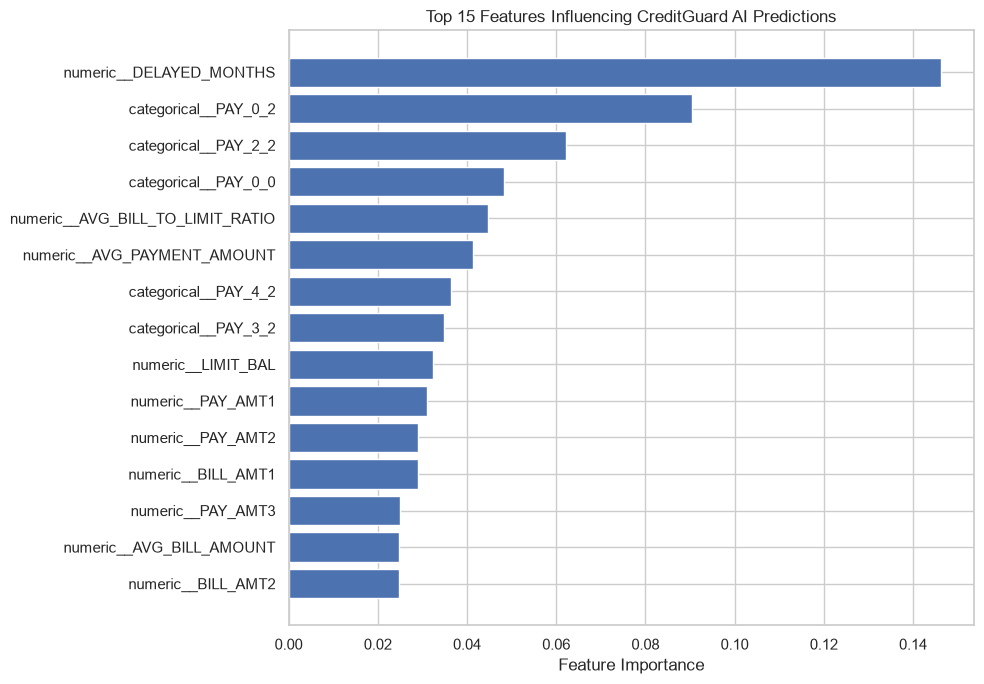

In [49]:
feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    best_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features Influencing CreditGuard AI Predictions")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.savefig("../outputs/feature_importance.png", dpi=300)
plt.show()

In [50]:
sample_customer = X_test.iloc[[0]]

prediction = best_model.predict(sample_customer)[0]
probability = best_model.predict_proba(sample_customer)[0, 1]

print("===== CREDITGUARD AI =====")

if prediction == 1:
    print("Prediction: Likely to Default")
else:
    print("Prediction: Unlikely to Default")

print(f"Estimated Default Probability: {probability:.2%}")

===== CREDITGUARD AI =====
Prediction: Unlikely to Default
Estimated Default Probability: 30.06%


In [51]:
importance_df.to_csv(
    "../outputs/feature_importance.csv",
    index=False
)

print("All final outputs saved!")
print("Model: ../models/creditguard_model.joblib")
print("Metrics: ../outputs/test_metrics.csv")
print("Feature importance: ../outputs/feature_importance.csv")

All final outputs saved!
Model: ../models/creditguard_model.joblib
Metrics: ../outputs/test_metrics.csv
Feature importance: ../outputs/feature_importance.csv


In [52]:
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
import ipywidgets as w
from IPython.display import display

In [54]:
import sys
print(sys.executable)

C:\Program Files\Python312\python.exe


In [55]:
import pandas as pd
import numpy as np

df = pd.read_excel(
    "../data/default of credit card clients.xls",
    header=1
)

df.columns = df.columns.astype(str).str.strip()
df = df.rename(columns={
    "default payment next month": "DEFAULT_NEXT_MONTH"
})

print("Dataset loaded:", df.shape)

Dataset loaded: (30000, 25)


In [56]:
from sklearn.ensemble import RandomForestClassifier

features = ["LIMIT_BAL", "BILL_AMT1", "PAY_0"]

X3 = df[features]
y3 = df["DEFAULT_NEXT_MONTH"]

model3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model3.fit(X3, y3)

print("CreditGuard AI is ready!")

CreditGuard AI is ready!


In [57]:

import pandas as pd

credit_limit = float(input("Enter Credit Limit (₹): "))
bill_amount = float(input("Enter Bill Amount (₹): "))
bank_balance = float(input("Enter Bank Balance (₹): "))
delay = int(input("Enter Payment Delay Status (-2 to 8): "))

if min(credit_limit, bill_amount, bank_balance) < 0 or not -2 <= delay <= 8:
    print("Invalid Input")

elif credit_limit < bank_balance:
    print("Credit Limit Exceeded")

else:
    customer = pd.DataFrame([{
        "LIMIT_BAL": credit_limit,
        "BILL_AMT1": bill_amount,
        "PAY_0": delay
    }])

    prediction = model3.predict(customer)[0]
    probability = model3.predict_proba(customer)[0, 1]

    print("\n--- CREDITGUARD AI PREDICTION ---")
    print("Prediction:",
          "Likely to Default" if prediction == 1
          else "Unlikely to Default")
    print(f"Estimated Default Probability: {probability:.2%}")

    print("\n--- BILL AFFORDABILITY ---")
    if bank_balance >= bill_amount:
        print("Result: Can Pay the Bill")
    else:
        print("Result: Cannot Pay the Full Bill")
        print(f"Amount Short: ₹{bill_amount - bank_balance:,.2f}")


Enter Credit Limit (₹):  50000
Enter Bill Amount (₹):  20000
Enter Bank Balance (₹):  10000
Enter Payment Delay Status (-2 to 8):  2



--- CREDITGUARD AI PREDICTION ---
Prediction: Likely to Default
Estimated Default Probability: 100.00%

--- BILL AFFORDABILITY ---
Result: Cannot Pay the Full Bill
Amount Short: ₹10,000.00


In [58]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(model3, "../models/creditguard_model.joblib")

print("Model saved successfully!")

Model saved successfully!
